In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
import warnings
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C4"
DTYPE="G_H"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C4_10,25,"[DATA/TRAINING/C4/C4_10/IMG_6597.HEIC, DATA/TR..."
1,C4_11,27,"[DATA/TRAINING/C4/C4_11/IMG_6727.HEIC, DATA/TR..."
2,C4_12,27,"[DATA/TRAINING/C4/C4_12/IMG_6857.HEIC, DATA/TR..."
3,C4_13,30,"[DATA/TRAINING/C4/C4_13/IMG_6998.HEIC, DATA/TR..."
4,C4_14,27,"[DATA/TRAINING/C4/C4_14/IMG_7250.HEIC, DATA/TR..."
5,C4_15,25,"[DATA/TRAINING/C4/C4_15/IMG_7388.HEIC, DATA/TR..."
6,C4_16,28,"[DATA/TRAINING/C4/C4_16/IMG_7517.HEIC, DATA/TR..."


In [4]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [5]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [7]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16 %')

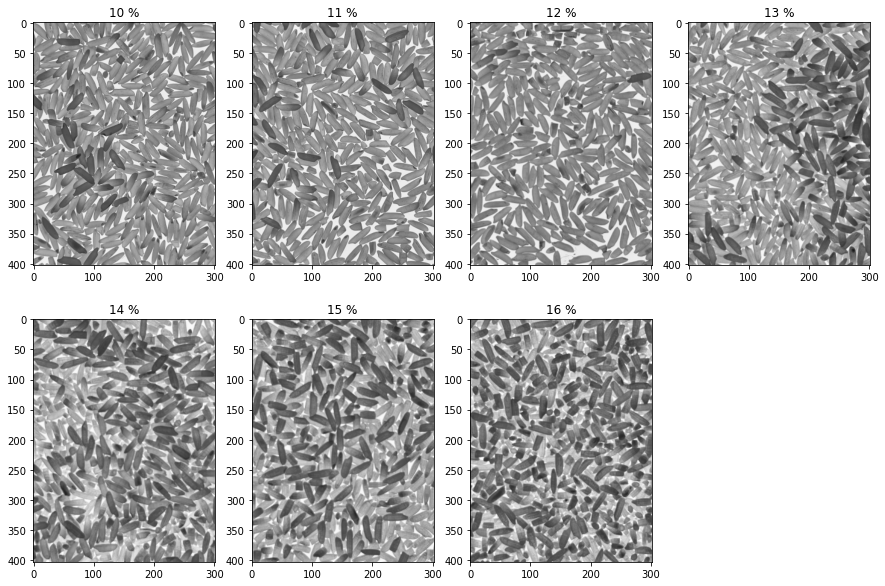

In [10]:
fig=plt.figure(figsize=(15, 10)) 
ax1 = fig.add_subplot(2,4,1)
image = read_imgHEIC(data_path[0][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10 %")
ax2 = fig.add_subplot(2,4,2)
image = read_imgHEIC(data_path[1][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11 %")
ax3 = fig.add_subplot(2,4,3)
image = read_imgHEIC(data_path[2][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12 %")
ax4 = fig.add_subplot(2,4,4)
image = read_imgHEIC(data_path[3][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13 %")
ax5 = fig.add_subplot(2,4,5)
image = read_imgHEIC(data_path[4][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14 %")
ax6 = fig.add_subplot(2,4,6)
image = read_imgHEIC(data_path[5][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15 %")
ax7 = fig.add_subplot(2,4,7)
image = read_imgHEIC(data_path[6][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16 %")

In [41]:
def fd_gray(gray, bins, mask=None):
    # compute the gray color histogram
    hist  = cv2.calcHist([gray], [0], None, [bins], [0, 256])
    # normalize the histogram
    cv2.normalize(hist, hist)
    # return the histogram
    return hist, hist.flatten()

In [158]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
bins=44; #width=2024; height=3032; 
scale=3
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        #Compute 1D gray histogram
        [grayHist, grayNormHist]=fd_gray(gray, bins)
        arr_img_hist.append(grayNormHist)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["bins"] = bins
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [159]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(bins)+'bins.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,41,42,43,scale,bins,height,width,channels,IMAGENAME,HUMIDITY
0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,...,0.031037,0.0,0.0,3,44,120,90,3,IMG_6597.HEIC,10
1,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,...,0.034598,0.0,0.0,3,44,120,90,3,IMG_6598.HEIC,10
2,0.0,0.0,0.0,0.0,0.0,0.0,0.000407,0.000407,0.000407,0.001221,...,0.066345,0.0,0.0,3,44,120,90,3,IMG_6599.HEIC,10
3,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000366,0.000000,0.001828,...,0.056657,0.0,0.0,3,44,120,90,3,IMG_6600.HEIC,10
4,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000356,...,0.055538,0.0,0.0,3,44,120,90,3,IMG_6601.HEIC,10
5,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,...,0.098377,0.0,0.0,3,44,120,90,3,IMG_6602.HEIC,10
6,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,...,0.060190,0.0,0.0,3,44,120,90,3,IMG_6603.HEIC,10
7,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000336,0.000000,...,0.027252,0.0,0.0,3,44,120,90,3,IMG_6604.HEIC,10
8,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,...,0.070406,0.0,0.0,3,44,120,90,3,IMG_6605.HEIC,10
9,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,...,0.036189,0.0,0.0,3,44,120,90,3,IMG_6606.HEIC,10


# Classification

In [160]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-7]
#X

In [161]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [162]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [163]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

### Random Forest Classifier

In [164]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [165]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.736842,0.773810,0.738095,0.755531,G_H,C4,RF_C,3,44,120,90,3
1,2,0.631579,0.666667,0.642857,0.654545,G_H,C4,RF_C,3,44,120,90,3
2,3,0.631579,0.723810,0.642857,0.680936,G_H,C4,RF_C,3,44,120,90,3
3,4,0.421053,0.454082,0.428571,0.440958,G_H,C4,RF_C,3,44,120,90,3
4,5,0.736842,0.809524,0.761905,0.784993,G_H,C4,RF_C,3,44,120,90,3
5,6,0.578947,0.559524,0.571429,0.565414,G_H,C4,RF_C,3,44,120,90,3
6,7,0.684211,0.714286,0.666667,0.689655,G_H,C4,RF_C,3,44,120,90,3
7,8,0.736842,0.857143,0.761905,0.806723,G_H,C4,RF_C,3,44,120,90,3
8,9,0.578947,0.645238,0.571429,0.606094,G_H,C4,RF_C,3,44,120,90,3
9,10,0.611111,0.666667,0.595238,0.628931,G_H,C4,RF_C,3,44,120,90,3


In [166]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,G_H,C4,RF_C,0.634795,0.638095,0.661378,0.687075


### MLP Classifier

In [167]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [168]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [169]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.473684,0.523810,0.500000,0.511628,G_H,C4,MLP_C,3,44,120,90,3
1,2,0.736842,0.752381,0.738095,0.745170,G_H,C4,MLP_C,3,44,120,90,3
2,3,0.631579,0.657143,0.642857,0.649922,G_H,C4,MLP_C,3,44,120,90,3
3,4,0.631579,0.657143,0.666667,0.661871,G_H,C4,MLP_C,3,44,120,90,3
4,5,0.631579,0.619048,0.642857,0.630728,G_H,C4,MLP_C,3,44,120,90,3
5,6,0.473684,0.442857,0.428571,0.435597,G_H,C4,MLP_C,3,44,120,90,3
6,7,0.631579,0.666667,0.619048,0.641975,G_H,C4,MLP_C,3,44,120,90,3
7,8,0.684211,0.776190,0.666667,0.717272,G_H,C4,MLP_C,3,44,120,90,3
8,9,0.473684,0.452381,0.476190,0.463980,G_H,C4,MLP_C,3,44,120,90,3
9,10,0.666667,0.714286,0.690476,0.702179,G_H,C4,MLP_C,3,44,120,90,3


In [170]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,G_H,C4,MLP_C,0.603509,0.607143,0.616032,0.62619


### XGBoost Classifier

In [171]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [172]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.473684,0.523810,0.476190,0.498866,G_H,C4,XGB_C,3,44,120,90,3
1,2,0.578947,0.535714,0.571429,0.552995,G_H,C4,XGB_C,3,44,120,90,3
2,3,0.631579,0.640476,0.642857,0.641664,G_H,C4,XGB_C,3,44,120,90,3
3,4,0.526316,0.642857,0.523810,0.577259,G_H,C4,XGB_C,3,44,120,90,3
4,5,0.526316,0.535714,0.547619,0.541601,G_H,C4,XGB_C,3,44,120,90,3
5,6,0.526316,0.476190,0.523810,0.498866,G_H,C4,XGB_C,3,44,120,90,3
6,7,0.684211,0.728571,0.666667,0.696246,G_H,C4,XGB_C,3,44,120,90,3
7,8,0.526316,0.523810,0.523810,0.523810,G_H,C4,XGB_C,3,44,120,90,3
8,9,0.631579,0.792857,0.642857,0.710021,G_H,C4,XGB_C,3,44,120,90,3
9,10,0.611111,0.630952,0.619048,0.624943,G_H,C4,XGB_C,3,44,120,90,3


In [173]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,G_H,C4,XGB_C,0.571637,0.57381,0.586627,0.603095


# External validation


In [174]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C4_10,5,"[DATA/TEST/C4/C4_10/IMG_6593.HEIC, DATA/TEST/C..."
1,C4_11,5,"[DATA/TEST/C4/C4_11/IMG_6718.HEIC, DATA/TEST/C..."
2,C4_12,5,"[DATA/TEST/C4/C4_12/IMG_6846.HEIC, DATA/TEST/C..."
3,C4_13,5,"[DATA/TEST/C4/C4_13/IMG_6983.HEIC, DATA/TEST/C..."
4,C4_14,5,"[DATA/TEST/C4/C4_14/IMG_7240.HEIC, DATA/TEST/C..."
5,C4_15,5,"[DATA/TEST/C4/C4_15/IMG_7378.HEIC, DATA/TEST/C..."
6,C4_16,5,"[DATA/TEST/C4/C4_16/IMG_7507.HEIC, DATA/TEST/C..."


In [175]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [176]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        #Compute 1D gray histogram
        [grayHist, grayNormHist]=fd_gray(gray, bins)
        arr_img_hist.append(grayNormHist)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["bins"] = bins
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [177]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(bins)+'bins.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,41,42,43,scale,bins,height,width,channels,IMAGENAME,HUMIDITY
0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000410,...,0.042280,0.000410,0.0,3,44,120,90,3,IMG_6593.HEIC,10
1,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.052488,0.000000,0.0,3,44,120,90,3,IMG_6594.HEIC,10
2,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.057072,0.000000,0.0,3,44,120,90,3,IMG_6595.HEIC,10
3,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.025519,0.000000,0.0,3,44,120,90,3,IMG_6596.HEIC,10
4,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.036189,0.000000,0.0,3,44,120,90,3,IMG_660.HEIC,10
0,0.0,0.0,0.0,0.0,0.0,0.000415,0.001659,0.000829,0.001244,0.003318,...,0.033176,0.002488,0.0,3,44,120,90,3,IMG_6718.HEIC,11
1,0.0,0.0,0.0,0.0,0.0,0.000827,0.000827,0.000827,0.001241,0.001654,...,0.035157,0.003723,0.0,3,44,120,90,3,IMG_6720.HEIC,11
2,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000362,...,0.044900,0.000362,0.0,3,44,120,90,3,IMG_6723.HEIC,11
3,0.0,0.0,0.0,0.0,0.0,0.000000,0.000740,0.001110,0.000370,0.000740,...,0.060334,0.006293,0.0,3,44,120,90,3,IMG_6725.HEIC,11
4,0.0,0.0,0.0,0.0,0.0,0.000000,0.000367,0.001466,0.000733,0.000367,...,0.057544,0.000733,0.0,3,44,120,90,3,IMG_6726.HEIC,11


In [178]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [179]:
X_test = dtFeaturesTest.values[:, :-7]
#X_test

In [180]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [181]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [182]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.67      0.40      0.50         5
     Class 1       0.57      0.80      0.67         5
     Class 2       0.57      0.80      0.67         5
     Class 3       0.50      0.60      0.55         5
     Class 4       0.50      0.40      0.44         5
     Class 5       0.67      0.40      0.50         5
     Class 6       0.80      0.80      0.80         5

    accuracy                           0.60        35
   macro avg       0.61      0.60      0.59        35
weighted avg       0.61      0.60      0.59        35



## MLP

In [183]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [184]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      0.60      0.75         5
     Class 1       0.67      0.80      0.73         5
     Class 2       0.57      0.80      0.67         5
     Class 3       0.43      0.60      0.50         5
     Class 4       0.50      0.40      0.44         5
     Class 5       0.60      0.60      0.60         5
     Class 6       0.67      0.40      0.50         5

    accuracy                           0.60        35
   macro avg       0.63      0.60      0.60        35
weighted avg       0.63      0.60      0.60        35



## XGBC

In [185]:
y_pred = modelXGBC.predict(X_test_scale) 

In [186]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.75      0.60      0.67         5
     Class 1       0.25      0.20      0.22         5
     Class 2       0.56      1.00      0.71         5
     Class 3       0.50      0.60      0.55         5
     Class 4       1.00      0.40      0.57         5
     Class 5       0.67      0.40      0.50         5
     Class 6       0.71      1.00      0.83         5

    accuracy                           0.60        35
   macro avg       0.63      0.60      0.58        35
weighted avg       0.63      0.60      0.58        35

